# DSCI 552 — Homework 5
**Name:** Alan Nhan  **USC ID:** 3907-9934-60 

### AI Use Disclosure

ChatGPT was used to assist with implementing and debugging Python code, organizing the notebook, and reviewing the assignment requirements. The results and outputs were reviewed for correctness.

**Example prompts used:**
- "How can I build and visualize a decision tree with multiple target labels?"
- "How do I extract IF-THEN rules from a decision tree?"
- "How can I use cross-validation to select the best pruning parameter?"
- "What's a good way to handle missing values in the Communities and Crime dataset?"
- "How do I compare Ridge, LASSO, PCR, and XGBoost using test MSE?"

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    KFold,
    GridSearchCV,
    cross_val_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

SEED = 42
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 80, 'font.size': 9})

## 1. Decision Trees as Interpretable Models
### 1(a) Data

In [2]:
cols = [
    'temp',
    'nausea',
    'lumbar_pain',
    'urine_pushing',
    'micturition_pain',
    'urethra_burning',
    'inflammation',
    'nephritis',
]
acute = pd.read_csv(
    'data/diagnosis.data',
    sep='\t',
    header=None,
    names=cols,
    encoding='utf-16',
    decimal=',',
)
X1 = acute.iloc[:, :6].replace({'yes': 1, 'no': 0}).astype(float)
Y1 = acute.iloc[:, 6:].eq('yes').astype(int)
print(acute.shape)
acute.head().T  # transposed preview to fit the page

(120, 8)


,0,1,2,3,4
temp,35.5,35.9,35.9,36.0,36.0
nausea,no,no,no,no,no
lumbar_pain,yes,no,yes,no,yes
urine_pushing,no,yes,no,yes,no
micturition_pain,no,yes,no,yes,no
urethra_burning,no,yes,no,yes,no
inflammation,no,yes,no,yes,no
nephritis,no,no,no,no,no


The file is UTF-16, tab-separated, and uses decimal commas for temperature. The five symptom predictors are encoded yes = 1 / no = 0. The two labels are bladder inflammation and nephritis of renal pelvis origin.

### 1(b) Decision Tree
I use the **label powerset** approach and map each (inflammation, nephritis) pair to one of four classes. This is the better fit here than binary relevance: all four combinations appear in the data, and the two diagnoses share symptoms, so one tree can model how they depend on each other.

{'inflammation': 40, 'nephritis': 31, 'neither': 30, 'both': 19}
leaves=6, depth=4, training accuracy=1.000


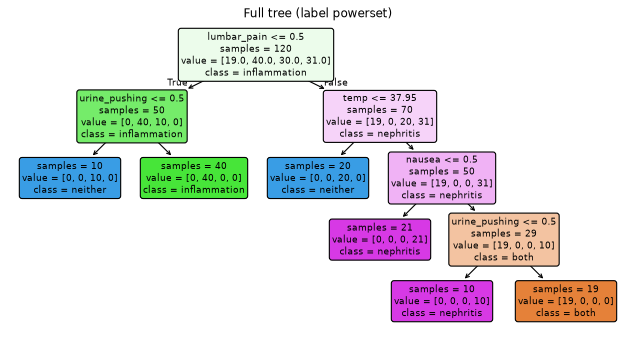

In [3]:
combo = {
    (0, 0): 'neither',
    (1, 0): 'inflammation',
    (0, 1): 'nephritis',
    (1, 1): 'both',
}
y1 = pd.Series([combo[tuple(r)] for r in Y1.values], name='diagnosis')
print(y1.value_counts().to_dict())

tree_full = DecisionTreeClassifier(random_state=SEED).fit(X1, y1)
print(
    f'leaves={tree_full.get_n_leaves()}, depth={tree_full.get_depth()}, '
    f'training accuracy={tree_full.score(X1, y1):.3f}'
)


def show_tree(model, ax, title):
    plot_tree(
        model,
        feature_names=X1.columns,
        class_names=model.classes_,
        filled=True,
        impurity=False,
        rounded=True,
        fontsize=8,
        ax=ax,
    )
    ax.set_title(title)


fig, ax = plt.subplots(figsize=(10, 5))
show_tree(tree_full, ax, 'Full tree (label powerset)')
plt.show()

### 1(c) IF-THEN Rules

In [4]:
def tree_rules(model, feats):
    t, rules = model.tree_, []

    def cond(f, thr, left):
        if f == 'temp':
            return f"temp {'<=' if left else '>'} {thr:.2f}"
        return f"{f} = {'no' if left else 'yes'}"

    def recurse(node, conds):
        if t.feature[node] < 0:
            label = model.classes_[t.value[node][0].argmax()]
            n = t.n_node_samples[node]
            rules.append(f"IF {' AND '.join(conds)} THEN {label}  (n={n})")
            return
        f, thr = feats[t.feature[node]], t.threshold[node]
        recurse(t.children_left[node], conds + [cond(f, thr, True)])
        recurse(t.children_right[node], conds + [cond(f, thr, False)])

    recurse(0, [])
    return rules


print('\n'.join(tree_rules(tree_full, X1.columns)))

IF lumbar_pain = no AND urine_pushing = no THEN neither  (n=10)
IF lumbar_pain = no AND urine_pushing = yes THEN inflammation  (n=40)
IF lumbar_pain = yes AND temp <= 37.95 THEN neither  (n=20)
IF lumbar_pain = yes AND temp > 37.95 AND nausea = no THEN nephritis  (n=21)
IF lumbar_pain = yes AND temp > 37.95 AND nausea = yes AND urine_pushing = no THEN nephritis  (n=10)
IF lumbar_pain = yes AND temp > 37.95 AND nausea = yes AND urine_pushing = yes THEN both  (n=19)


### 1(d) Cost-Complexity Pruning
I pick α with 10×-repeated stratified 5-fold CV over the pruning path, using the **one-standard-error rule**: the largest α whose mean CV accuracy is within one SE of the best. This favors the smallest tree that performs about as well as the best one.

In [5]:
alphas = tree_full.cost_complexity_pruning_path(X1, y1).ccp_alphas
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
rows = []
for a in alphas:
    m = DecisionTreeClassifier(random_state=SEED, ccp_alpha=a)
    s = cross_val_score(m, X1, y1, cv=rcv)
    m.fit(X1, y1)
    rows.append(
        {
            'ccp_alpha': a,
            'leaves': m.get_n_leaves(),
            'cv_acc': s.mean(),
            'cv_se': s.std(ddof=1) / np.sqrt(len(s)),
            'train_acc': m.score(X1, y1),
        }
    )
path = pd.DataFrame(rows)
best = path.loc[path.cv_acc.idxmax()]
alpha_1se = path.loc[
    path.cv_acc >= best.cv_acc - best.cv_se, 'ccp_alpha'
].max()
print(f'Selected ccp_alpha (1-SE rule) = {alpha_1se:.4f}')
path.round(4)

Selected ccp_alpha (1-SE rule) = 0.0000


,ccp_alpha,leaves,cv_acc,cv_se,train_acc
0,0.0000,6,0.9900,0.0030,1.0000
1,0.0982,4,0.8500,0.0095,0.8417
2,0.1333,3,0.7558,0.0080,0.7583
3,0.1820,2,0.6725,0.0094,0.5917
4,0.2229,1,0.4917,0.0178,0.3333


CV-selected tree: 6 leaves, same as full: True


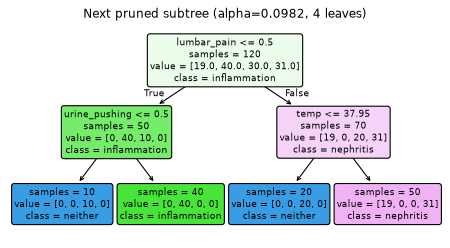

IF lumbar_pain = no AND urine_pushing = no THEN neither  (n=10)
IF lumbar_pain = no AND urine_pushing = yes THEN inflammation  (n=40)
IF lumbar_pain = yes AND temp <= 37.95 THEN neither  (n=20)
IF lumbar_pain = yes AND temp > 37.95 THEN nephritis  (n=50)


In [6]:
tree_cv = DecisionTreeClassifier(
    random_state=SEED, ccp_alpha=alpha_1se
).fit(X1, y1)
same = tree_rules(tree_cv, X1.columns) == tree_rules(tree_full, X1.columns)
print(
    f'CV-selected tree: {tree_cv.get_n_leaves()} leaves, same as full: {same}'
)
alpha_small = alphas[alphas > alpha_1se].min()  # next pruning level
tree_small = DecisionTreeClassifier(
    random_state=SEED, ccp_alpha=alpha_small
)
tree_small.fit(X1, y1)

fig, ax = plt.subplots(figsize=(7, 3.5))
show_tree(
    tree_small,
    ax,
    f'Next pruned subtree (alpha={alpha_small:.4f}, '
    f'{tree_small.get_n_leaves()} leaves)',
)
plt.show()
print('\n'.join(tree_rules(tree_small, X1.columns)))

With the 1-SE rule, CV picks α = 0. The CV-selected tree is the original 6-leaf tree, so its plot and rules are the ones in 1(b) and 1(c). It is already the smallest tree on the cost-complexity path that loses no accuracy: CV accuracy is 0.990, and the very next pruning step drops it to 0.850. That next subtree (4 leaves) is simpler, but it merges the `nausea`/`urine_pushing` splits and can no longer predict **both**, which misclassifies all 19 of those patients (training accuracy 0.842). I therefore keep the 6-rule tree as the minimal interpretable model. Its rules are easy to read: urine pushing without lumbar pain indicates inflammation, and lumbar pain with temperature > 37.95 °C indicates nephritis.

## 2. LASSO and Boosting for Regression
### 2(a) Data

In [7]:
with open('data/communities.names') as f:
    names = re.findall(r'^@attribute (\S+)', f.read(), flags=re.M)
crime = pd.read_csv(
    'data/communities.data', header=None, names=names, na_values='?'
)
target = 'ViolentCrimesPerPop'
print(crime.shape)
crime.iloc[:3, :7]

(1994, 128)


,state,county,community,communityname,fold,population,householdsize
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42


Column names come from the `@attribute` lines in `communities.names`. The target is `ViolentCrimesPerPop`. I keep the original row order, so rows 1–1495 form the training set and rows 1496–1994 the test set.

### 2(b) Missing Data
The description lists `state`, `county`, `community`, `communityname`, and `fold` as non-predictive, so I drop them and keep 122 predictors. Missing values (`?`) are filled with the **training-set median**. In the models below, the imputer sits inside each pipeline, so during CV it is refit on each training fold.

In [8]:
crime = crime.drop(
    columns=['state', 'county', 'community', 'communityname', 'fold']
)
train, test = crime.iloc[:1495], crime.iloc[1495:]
X_tr, y_tr = train.drop(columns=target), train[target]
X_te, y_te = test.drop(columns=target), test[target]
print(f'train {X_tr.shape}, test {X_te.shape}')

miss = crime.isna().sum()
miss = miss[miss > 0]
print(
    f'{len(miss)} features have missing values; '
    f'target missing: {crime[target].isna().sum()}'
)
print('Missing count -> number of features:', miss.value_counts().to_dict())

imputer = SimpleImputer(strategy='median').fit(X_tr)
X_tr_imp = pd.DataFrame(
    imputer.transform(X_tr), columns=X_tr.columns, index=X_tr.index
)

train (1495, 122), test (499, 122)
23 features have missing values; target missing: 0
Missing count -> number of features: {1675: 22, 1: 1}


Most missing values come from 22 LEMAS police features that are missing in about 84% of communities. `OtherPerCap` is missing once. Parts (c)–(e) are exploratory, and I compute them on the imputed **training** set so the test set is never used.

### 2(c) Correlation Matrix

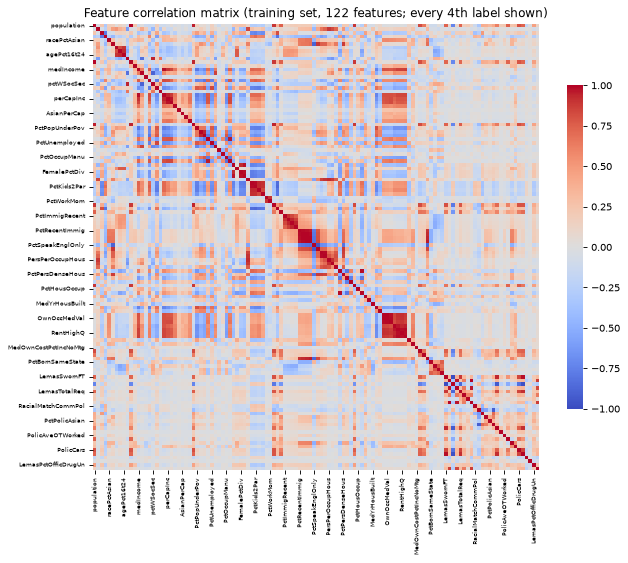

Most correlated feature pairs:


LemasSwFTPerPop  PolicPerPop          1.0000
PctRecImmig8     PctRecImmig10        0.9956
OwnOccLowQuart   OwnOccMedVal         0.9947
LemasSwornFT     LemasSwFTFieldOps   -0.9945
population       numbUrban            0.9936
dtype: float64

In [9]:
corr = X_tr_imp.corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
    xticklabels=4,
    yticklabels=4,
    cbar_kws={'shrink': 0.7},
)
ax.tick_params(labelsize=5)
ax.set_title(
    'Feature correlation matrix (training set, 122 features; '
    'every 4th label shown)'
)
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
print('Most correlated feature pairs:')
upper.reindex(upper.abs().sort_values(ascending=False).index).head(5).round(
    4
)

The heatmap shows large blocks of strongly correlated features: population counts, income/poverty measures, immigration variables, and the police (LEMAS) variables. Some pairs are nearly redundant (|r| ≈ 1). This collinearity makes plain least squares unstable and is the motivation for ridge, LASSO, and PCR below.

### 2(d) Coefficient of Variation

In [10]:
means, stds = X_tr_imp.mean(), X_tr_imp.std(ddof=1)
# CV is undefined (NaN) when the mean is ~0
cv = np.where(means.abs() > 1e-8, stds / means, np.nan)
cv_df = pd.DataFrame({'mean': means, 'std': stds, 'CV': cv})
cv_df = cv_df.sort_values('CV', ascending=False)
print(
    f'{len(cv_df)} features; undefined CV: {cv_df.CV.isna().sum()}; '
    f'min |mean| = {means.abs().min():.4f}'
)
pd.concat([cv_df.head(6), cv_df.tail(3)]).round(3)

122 features; undefined CV: 0; min |mean| = 0.0163


,mean,std,CV
PctPolicAsian,0.016,0.090,5.527
NumStreet,0.023,0.099,4.293
NumInShelters,0.030,0.103,3.471
NumIlleg,0.037,0.114,3.059
NumImmig,0.031,0.090,2.927
LemasPctOfficDrugUn,0.093,0.238,2.553
PctPolicWhite,0.763,0.091,0.119
LemasPctPolicOnPatr,0.752,0.084,0.112
LemasSwFTFieldOps,0.962,0.062,0.064


The full 122-row table is in `cv_df`; above are the 6 highest and 3 lowest CVs. Any feature with |m| ≤ 1e-8 would get an undefined CV, but no feature comes close (smallest mean ≈ 0.016). The top CV belongs to `PctPolicAsian`. It is inflated because most of its values were imputed with the training median, which is near 0.

### 2(e) Top-CV Features

Top 11 CV features: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'LemasSwornFT', 'population', 'numbUrban', 'HousVacant']


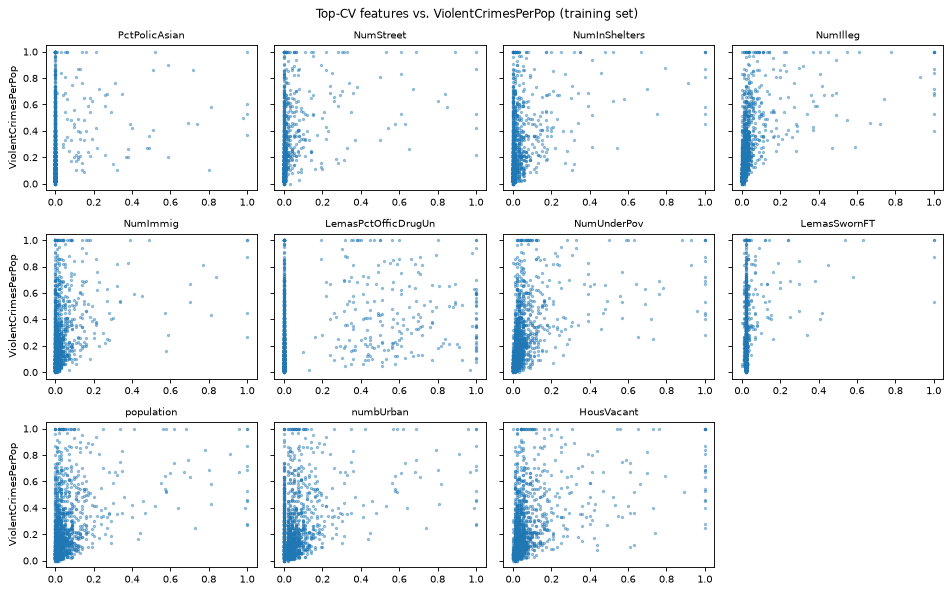

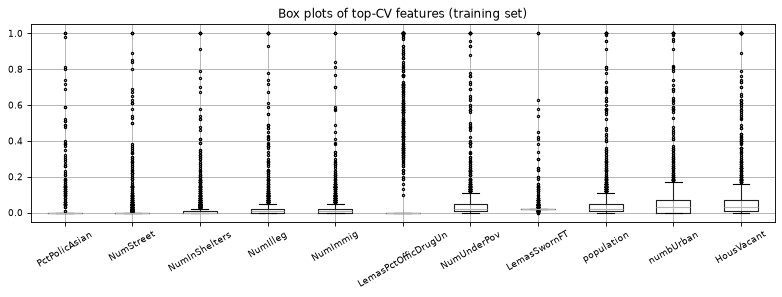

In [11]:
k = int(np.floor(np.sqrt(128)))
top = cv_df.CV.dropna().index[:k].tolist()
print(f'Top {k} CV features: {top}')

fig, axes = plt.subplots(3, 4, figsize=(12, 7.5), sharey=True)
for ax, f in zip(axes.flat, top):
    ax.scatter(X_tr_imp[f], y_tr, s=4, alpha=0.4)
    ax.set_title(f, fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel(target)
axes.flat[-1].axis('off')
plt.suptitle('Top-CV features vs. ViolentCrimesPerPop (training set)')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 3.2))
X_tr_imp[top].boxplot(
    ax=ax, rot=30, fontsize=8, flierprops={'markersize': 2}
)
ax.set_title('Box plots of top-CV features (training set)')
plt.show()

**No.** A scatter plot shows only the marginal relationship between one feature and the response. It does not account for the other 121 correlated features or for sampling noise. To judge significance you need a fitted model and a formal test, such as coefficient t-tests or p-values. These high-CV features are also mostly heavily right-skewed counts, so a few large communities dominate the plots.

### 2(f) Linear Regression (OLS)

In [12]:
kf = KFold(n_splits=10, shuffle=True, random_state=SEED)
imp = lambda: SimpleImputer(strategy='median')
mse = lambda model: mean_squared_error(y_te, model.predict(X_te))
results = {}

ols = make_pipeline(imp(), LinearRegression()).fit(X_tr, y_tr)
results['OLS'] = ('—', mse(ols))
print(f'OLS test MSE = {results["OLS"][1]:.4f}')

OLS test MSE = 0.0180


### 2(g) Ridge Regression

In [13]:
def tune(pipe, grid):
    gs = GridSearchCV(
        pipe, grid, cv=kf, scoring='neg_mean_squared_error', n_jobs=-1
    )
    return gs.fit(X_tr, y_tr)


ridge = tune(
    make_pipeline(imp(), Ridge()), {'ridge__alpha': np.logspace(-3, 3, 61)}
)
a = ridge.best_params_['ridge__alpha']
results['Ridge'] = (f'λ = {a:.4g}', mse(ridge))
print(f'Ridge: λ = {a:.4g}, test MSE = {results["Ridge"][1]:.4f}')

Ridge: λ = 3.162, test MSE = 0.0175


### 2(h) LASSO

In [14]:
lasso_grid = {'lasso__alpha': np.logspace(-6, -1, 51)}
lasso_raw = tune(make_pipeline(imp(), Lasso(max_iter=50000)), lasso_grid)
lasso_std = tune(
    make_pipeline(imp(), StandardScaler(), Lasso(max_iter=50000)),
    lasso_grid,
)

selected = {}
for name, gs in [
    ('LASSO (original scale)', lasso_raw),
    ('LASSO (standardized)', lasso_std),
]:
    a, coef = gs.best_params_['lasso__alpha'], gs.best_estimator_[-1].coef_
    selected[name] = X_tr.columns[coef != 0].tolist()
    results[name] = (f'λ = {a:.4g}', mse(gs))
    print(
        f'{name}: λ = {a:.4g}, test MSE = {results[name][1]:.4f}, '
        f'{len(selected[name])}/122 variables selected'
    )
    print('  ' + ', '.join(selected[name]) + '\n')
s_raw, s_std = map(set, selected.values())
print(f'Selected by both: {len(s_raw & s_std)}')
print(f'Only original scale: {sorted(s_raw - s_std)}')
print(f'Only standardized: {sorted(s_std - s_raw)}')

LASSO (original scale): λ = 0.0001259, test MSE = 0.0176, 74/122 variables selected
  racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctBornSameState, PctSameCity85, LemasSwFTFieldPerPop, PolicReqPerOffic, RacialMatchCo

The two LASSO fits are nearly identical: test MSE is 0.0176 vs. 0.0177, and 73 of their 74/76 selected variables are shared. That is expected, because the features are already normalized to [0, 1] and standardizing changes each feature's relative penalty only slightly. Both drop about 40% of the predictors and still match or beat OLS on the test set.

### 2(i) Principal Component Regression

In [15]:
pcr = tune(
    make_pipeline(
        imp(), StandardScaler(), PCA(random_state=SEED), LinearRegression()
    ),
    {'pca__n_components': range(1, X_tr.shape[1] + 1)},
)
M = pcr.best_params_['pca__n_components']
results['PCR'] = (f'M = {M}', mse(pcr))
print(f'PCR: M = {M}, test MSE = {results["PCR"][1]:.4f}')

PCR: M = 95, test MSE = 0.0183


CV keeps 95 of 122 components, so PCR achieves little dimension reduction here. Its test MSE is slightly worse than OLS. PCA is unsupervised, so the high-variance directions it keeps are not necessarily the ones most predictive of violent crime.

### 2(j) XGBoost with L1 Regularization

Standard XGBoost does not fit a LASSO regression at each node; its trees still predict constant leaf values. What `reg_alpha` adds is an L1 penalty on those leaf weights, which shrinks them toward zero. That is the "L1-penalized" part I tune here with 10-fold CV. The other settings are fixed at moderate values (500 trees, learning rate 0.03, depth 3, row/column subsampling) and are not tuned.

In [16]:
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.5,
    random_state=SEED,
    n_jobs=1,
)
xgb = tune(
    make_pipeline(imp(), xgb_model),
    {'xgbregressor__reg_alpha': [0, 0.001, 0.01, 0.05, 0.1, 0.5, 1, 2, 5]},
)
a = xgb.best_params_['xgbregressor__reg_alpha']
results['XGBoost'] = (f'reg_alpha = {a:g}', mse(xgb))
print(f'XGBoost: reg_alpha = {a:g}, test MSE = {results["XGBoost"][1]:.4f}')

XGBoost: reg_alpha = 0.1, test MSE = 0.0157


## Model Comparison

In [17]:
summary = pd.DataFrame(
    results, index=['Selected hyperparameter', 'Test MSE']
).T
summary['Test MSE'] = summary['Test MSE'].astype(float).round(4)
summary.sort_values('Test MSE')

,Selected hyperparameter,Test MSE
XGBoost,reg_alpha = 0.1,0.0157
Ridge,λ = 3.162,0.0175
LASSO (original scale),λ = 0.0001259,0.0176
LASSO (standardized),λ = 0.000631,0.0177
OLS,—,0.0180
PCR,M = 95,0.0183


XGBoost has the lowest test MSE (0.0157), about 10% below the best linear model (ridge, 0.0175). The linear models are all close together (0.0175–0.0183), with ridge and LASSO slightly ahead of OLS and PCR. These numbers come from a single train/test split, so the small differences among the linear models should not be overinterpreted.

## References
- Czerniak, J. & Zarzycki, H. *Acute Inflammations* dataset, UCI Machine Learning Repository.
- Redmond, M. *Communities and Crime* dataset, UCI Machine Learning Repository.
- KDnuggets (2017), "Simplifying Decision Tree Interpretability with Python & Scikit-learn" (tree-to-rules idea).
- James, Witten, Hastie & Tibshirani, *An Introduction to Statistical Learning*, 2nd ed. (cost-complexity pruning, ridge, LASSO, PCR).